# 03b · Significant topic routes between communities (backbone prototype)

RQ1 says *how often* a topic crosses community boundaries. This notebook asks **along which routes**: when
content of topic *t* leaves community X, which communities Y does it go to **more than expected**?
Settings fixed before running: `docs/DECISIONS.md` **D21**. This is a prototype for discussion with
Jussara.

**How it works**
1. For each topic, build a small network whose nodes are communities (notebook 02). Edge X → Y = number
   of English–English text forwards of that topic written in X and reposted in Y (X ≠ Y: crossing
   forwards only).
2. Apply the **noise-corrected backbone** (Coscia & Neffke 2017) to that network. Expected X → Y =
   (topic-*t* forwards X sends to other communities) × (topic-*t* forwards Y receives from other
   communities) / (all topic-*t* crossing forwards). A route is **significant** if its lift over that
   expectation is above zero by more than 1.64 standard deviations.
3. The same over all topics gives the reference: the routes crossing content uses in general.

Community conspiracy level (display only): **high** ≥ 30% of channels in the conspiracy list, **low**
< 10%, **middle** otherwise. Edge direction: content flow, `src -> dest`.

**Caveat:** topics here are the source channel's LDA topic (interim). Routes partly reflect channel types;
the real result needs message-level topics (notebook 04).

In [1]:
import json, random, sys
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path("src").resolve()))
from tgperm import config as cfg, data, plots, backbone

plots.use_style()
OUT = cfg.RESULTS / "03b"   # this notebook's tables and figures
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.max_colwidth", 70, "display.width", 220)

con = data.connect()
channels = data.channel_table(con).set_index("channel_id")
community = pd.read_parquet(cfg.DERIVED / "communities.parquet").set_index("channel_id").community
fw = pd.read_parquet(data.build_en_text_windows(con))
fw = fw.assign(topic=fw.src_id.map(channels.ch_topic),
               src_c=fw.src_id.map(community).to_numpy(), dst_c=fw.dest_id.map(community).to_numpy())
cross = fw[fw.src_c != fw.dst_c]
print(f"crossing English–English text forwards: {cross.n_text.sum():,} of {fw.n_text.sum():,}, "
      f"between {cross.src_c.nunique()} source and {cross.dst_c.nunique()} destination communities")

# Community descriptors: conspiracy level (all channels), main channel topic and size (English channels)
mem = channels.join(community, how="inner")
comm = mem.groupby("community").agg(channels=("conspiracy", "size"), conspiracy_share=("conspiracy", "mean"))
en = mem[mem.language == "en"]
comm["english_channels"] = en.groupby("community").size().reindex(comm.index, fill_value=0)
comm["main_topic"] = en.groupby("community").ch_topic.agg(lambda s: s.value_counts().index[0])
comm["level"] = np.select([comm.conspiracy_share >= 0.30, comm.conspiracy_share < 0.10], ["high", "low"], "middle")
# Names read from each community's most reposted channels (notebook 02, Fig. 2); never from LDA labels
NAMES = {0: "Russian news", 1: "Russian memes", 2: "Iranian news", 3: "Uzbek news", 4: "memes & entertainment",
         5: "German conspiracy", 6: "far-right & conspiracy", 7: "right-wing news & Covid", 8: "gaming & shops",
         9: "Iraqi channels", 10: "Ukrainian news", 11: "East African channels", 12: "Spanish conspiracy",
         13: "Russian sports", 14: "adult content", 15: "Hong Kong news", 16: "Indian education", 29: "Sabmyk"}
comm["main_language"] = mem.groupby("community").language.agg(lambda s: s.fillna("no label").value_counts().index[0])
comm["name"] = [NAMES.get(c, l) for c, l in zip(comm.index, comm.main_language)]
comm["label"] = [f"C{c} · {n} · {p:.0%} consp." for c, n, p in zip(comm.index, comm.name, comm.conspiracy_share)]
print(comm[comm.english_channels >= 30].level.value_counts().to_string())

crossing English–English text forwards: 386,975 of 7,731,006, between 58 source and 50 destination communities
level
low       16
high       5
middle     1


## 1 · Routes per topic

`routes used` = community pairs with at least one crossing forward of the topic; `on significant routes`
= share of the topic's crossing forwards that travel on significant routes; `high → low` = share of the
topic's crossing forwards going from a high-conspiracy to a low-conspiracy community, in total and on
significant routes.

In [2]:
def routes_for(d):
    r = d.groupby(["src_c", "dst_c"], as_index=False).n_text.sum().rename(
        columns={"src_c": "src_id", "dst_c": "dest_id", "n_text": "weight"})
    r = pd.concat([r, backbone.noise_corrected(r)], axis=1)
    r["significant"] = backbone.keep_nc(r)
    ni = r.groupby("src_id").weight.transform("sum"); nj = r.groupby("dest_id").weight.transform("sum")
    r["expected"] = ni * nj / r.weight.sum()
    r["lift"] = r.weight / r.expected
    r["share_of_topic_crossing"] = r.weight / r.weight.sum()
    r["src_level"] = r.src_id.map(comm.level).to_numpy(); r["dst_level"] = r.dest_id.map(comm.level).to_numpy()
    return r

topics = sorted(cross.topic.unique())
R = {"all topics": routes_for(cross)} | {t: routes_for(cross[cross.topic == t]) for t in topics}
allr = pd.concat(R, names=["topic"]).reset_index(level=0)

def summary(r):
    hl = (r.src_level == "high") & (r.dst_level == "low")
    return {"crossing forwards": int(r.weight.sum()), "routes used": len(r), "significant routes": int(r.significant.sum()),
            "on significant routes": r.weight[r.significant].sum() / r.weight.sum(),
            "high → low (all routes)": r.weight[hl].sum() / r.weight.sum(),
            "high → low (significant routes)": r.weight[hl & r.significant].sum() / r.weight.sum()}

summ = pd.DataFrame({t: summary(r) for t, r in R.items()}).T.sort_values("crossing forwards", ascending=False)
summ.style.format({"crossing forwards": "{:,.0f}", "routes used": "{:,.0f}", "significant routes": "{:,.0f}",
                   "on significant routes": "{:.0%}", "high → low (all routes)": "{:.1%}",
                   "high → low (significant routes)": "{:.1%}"})

,crossing forwards,routes used,significant routes,on significant routes,high → low (all routes),high → low (significant routes)
all topics,"386,975",354,179,97%,2.6%,2.1%
US news,"170,148",97,47,99%,1.4%,1.2%
World news,"77,586",90,54,95%,2.2%,1.8%
Covid,"74,066",57,34,99%,1.7%,1.1%
Religion,"29,661",137,77,94%,8.3%,7.2%
Extremists and radicals,"12,042",50,28,98%,7.4%,7.4%
Entertainment,"7,327",63,40,92%,1.2%,1.1%
Porn,"5,025",48,31,96%,6.0%,5.1%
Software,"3,395",91,51,87%,25.4%,18.1%
Crypto,"3,192",47,32,96%,0.8%,0.7%


## 2 · The significant routes

Largest significant routes of the reference (all topics) and of the five topics with the most crossing
forwards. `lift` = observed / expected forwards on the route.

In [3]:
def show_routes(t, k=8):
    r = R[t]
    s = r[r.significant].sort_values("weight", ascending=False).head(k)
    return pd.DataFrame({"from": s.src_id.map(comm.label).to_numpy(), "to": s.dest_id.map(comm.label).to_numpy(),
                         "forwards": s.weight.to_numpy(), "share of topic's crossing": s.share_of_topic_crossing.to_numpy(),
                         "lift": s.lift.to_numpy()})

panel_topics = ["all topics"] + summ.drop("all topics").index[:5].tolist()
for t in panel_topics:
    print(f"\n=== {t}: {summ.loc[t, 'significant routes']:.0f} significant routes carrying "
          f"{summ.loc[t, 'on significant routes']:.0%} of {summ.loc[t, 'crossing forwards']:,.0f} crossing forwards")
    print(show_routes(t).to_string(index=False, formatters={"forwards": "{:,}".format,
          "share of topic's crossing": "{:.1%}".format, "lift": "{:.1f}".format}))


=== all topics: 179 significant routes carrying 97% of 386,975 crossing forwards
                                     from                                        to forwards share of topic's crossing lift
C7 · right-wing news & Covid · 67% consp.  C6 · far-right & conspiracy · 35% consp.  185,989                     48.1%  1.7
 C6 · far-right & conspiracy · 35% consp. C7 · right-wing news & Covid · 67% consp.  104,760                     27.1%  2.7
                C29 · Sabmyk · 86% consp. C7 · right-wing news & Covid · 67% consp.   14,816                      3.8%  2.7
   C4 · memes & entertainment · 4% consp.  C6 · far-right & conspiracy · 35% consp.   12,513                      3.2%  1.3
C7 · right-wing news & Covid · 67% consp.       C5 · German conspiracy · 51% consp.   12,498                      3.2%  1.8
 C6 · far-right & conspiracy · 35% consp.    C4 · memes & entertainment · 4% consp.    5,684                      1.5%  2.1
C7 · right-wing news & Covid · 67% consp.     C12 

**Out of the conspiracy sphere.** Significant routes from a high-conspiracy community to a low-conspiracy
community, for every topic: the pathways by which content from conspiracy-heavy communities reaches
communities where conspiracy channels are rare.

In [4]:
hl = allr[(allr.topic != "all topics") & allr.significant & (allr.src_level == "high") & (allr.dst_level == "low")]
hl = hl.assign(**{"from": hl.src_id.map(comm.label), "to": hl.dest_id.map(comm.label)}).sort_values("weight", ascending=False)
hl[["topic", "from", "to", "weight", "share_of_topic_crossing", "lift"]].head(20).style.format(
    {"weight": "{:,}", "share_of_topic_crossing": "{:.1%}", "lift": "{:.1f}"}).hide(axis="index")

topic,from,to,weight,share_of_topic_crossing,lift
Religion,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,"1,974",6.7%,1.3
World news,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,975,1.3%,2.4
US news,C7 · right-wing news & Covid · 67% consp.,C15 · Hong Kong news · 5% consp.,954,0.6%,1.5
Extremists and radicals,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,832,6.9%,1.5
US news,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,733,0.4%,2.9
Software,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,540,15.9%,1.5
Covid,C7 · right-wing news & Covid · 67% consp.,C15 · Hong Kong news · 5% consp.,505,0.7%,1.4
World news,C7 · right-wing news & Covid · 67% consp.,C15 · Hong Kong news · 5% consp.,260,0.3%,1.3
Porn,C6 · far-right & conspiracy · 35% consp.,C4 · memes & entertainment · 4% consp.,255,5.1%,1.5
US news,C7 · right-wing news & Covid · 67% consp.,C61 · en · 0% consp.,186,0.1%,1.6


**Gateway communities.** Where do the crossing forwards that go from a high- to a low-conspiracy
community end up? *Gateway* is a descriptive name, not a test: the low-conspiracy communities that
receive the largest share of these forwards (all topics, all routes).

In [5]:
a = R["all topics"]
hl_all = a[(a.src_level == "high") & (a.dst_level == "low")]
gate = (hl_all.groupby("dest_id").weight.sum().sort_values(ascending=False).rename("forwards").to_frame()
        .assign(share=lambda d: d.forwards / d.forwards.sum(), cumulative=lambda d: d.share.cumsum(),
                community=lambda d: d.index.map(comm.label)))
print(f"high → low crossing forwards (all topics): {hl_all.weight.sum():,} = {hl_all.weight.sum() / a.weight.sum():.2%} "
      f"of {a.weight.sum():,} crossing forwards")
gate.head(6)[["community", "forwards", "share", "cumulative"]].style.format(
    {"forwards": "{:,}", "share": "{:.1%}", "cumulative": "{:.1%}"})

high → low crossing forwards (all topics): 10,248 = 2.65% of 386,975 crossing forwards


,community,forwards,share,cumulative
dest_id,,,,
4,C4 · memes & entertainment · 4% consp.,"6,803",66.4%,66.4%
15,C15 · Hong Kong news · 5% consp.,"2,176",21.2%,87.6%
1,C1 · Russian memes · 3% consp.,266,2.6%,90.2%
11,C11 · East African channels · 1% consp.,248,2.4%,92.6%
23,C23 · en · 2% consp.,221,2.2%,94.8%
61,C61 · en · 0% consp.,199,1.9%,96.7%


**Who are the gateways?** The dataset's labels describe a community poorly when most of its channels
have no language label (channel topics exist only for English channels), or when the LDA topic is
misleading. So, for the two main gateways: languages, the English channel-topic mix, and the 10
channels whose posts are reposted most (times reposted by other channels, full graph). The descriptions
used in the text ("memes", "Hong Kong") are read from these lists.

In [6]:
times_reposted = pd.read_parquet(cfg.DERIVED / "edges_full.parquet", columns=["src_id", "weight"]).groupby("src_id").weight.sum()
for c in gate.index[:2]:
    m = mem[mem.community == c]
    langs = m.language.fillna("unknown").value_counts(normalize=True).head(3)
    tops = m[m.language == "en"].ch_topic.value_counts(normalize=True).head(3)
    print(f"C{c}: {len(m):,} channels, {m.conspiracy.mean():.0%} conspiracy; languages: "
          + ", ".join(f"{k} {v:.0%}" for k, v in langs.items())
          + "; English channel topics: " + ", ".join(f"{k} {v:.0%}" for k, v in tops.items()))
    top = m.assign(times_reposted=times_reposted.reindex(m.index).fillna(0).astype(int)).nlargest(10, "times_reposted")
    print(top[["username", "title", "language", "ch_topic", "times_reposted"]].to_string(), "\n")

C4: 6,386 channels, 4% conspiracy; languages: en 35%, unknown 34%, it 22%; English channel topics: Religion 41%, Entertainment 32%, Software 6%
                       username                        title language       ch_topic  times_reposted
channel_id                                                                                          
1142271647            dadoem_mv               eternal cringe       en       Religion           86487
1254320847       AnimeBirthdays             🎂 AnimeBirthdays       en  Entertainment           18876
1101425425       PoliticalMemes              Political memes       en     World news           17067
1097902914             shitpost    Shitpost | shitposting.io      NaN            NaN           15429
1273142419            applebeas                   Syndiegram       en       Religion           15005
1330744411            tonino_28           ｚｉｏ ｔｏｎｉｎｏ ｐｏｓｔｉｎｇ       en  Entertainment           14522
1541543072       eternalclassic              ete

## 3 · Figure: route maps

**Figure 1.** The main significant routes (noise-corrected backbone, δ = 1.64) for crossing English text
forwards: all topics and the five topics with the most crossings. Only routes carrying **≥ 2%** of the
topic's crossing forwards are drawn. Node = community, placed by conspiracy level (high left, low right, ordered by crossing volume); arrow
width ∝ share of the topic's crossings (labelled when ≥ 5%); **red arrows go from a high- to a
low-conspiracy community**, the only ones that cross the figure. Same positions in every panel. Topic = source channel's label (interim).

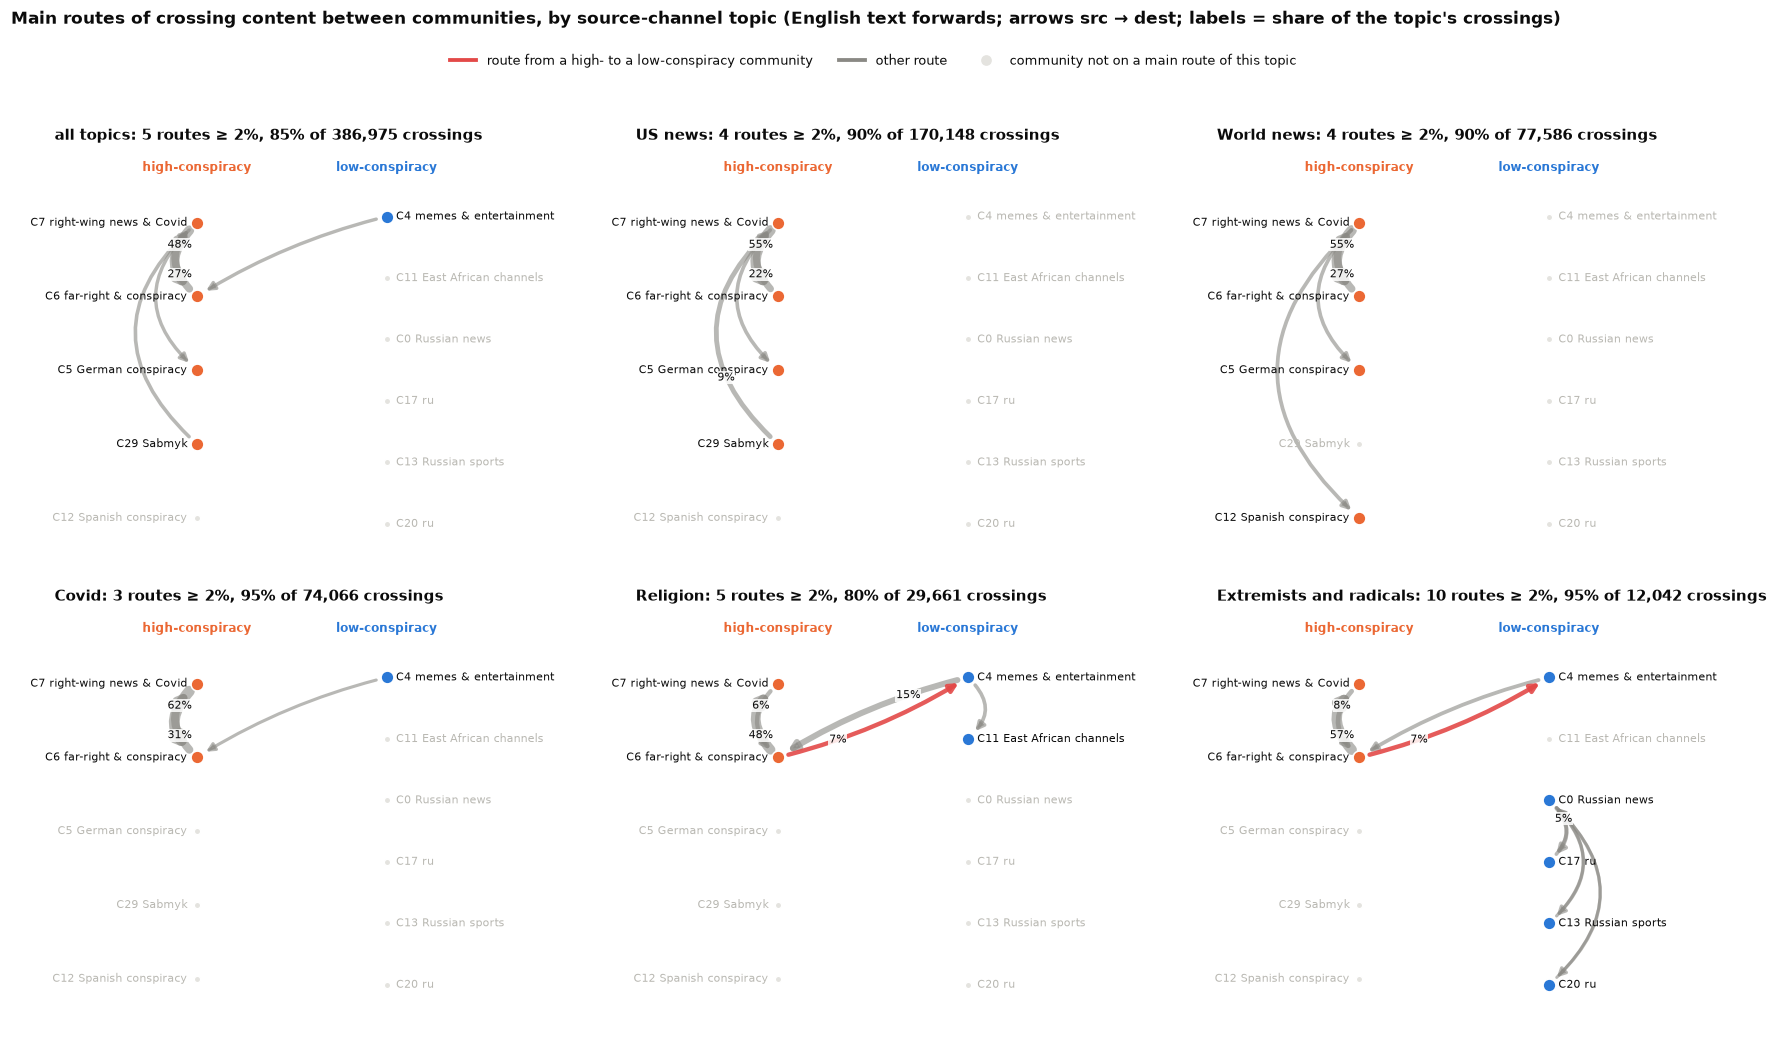

In [7]:
LEVEL_COLOR = {"high": plots.SERIES[1], "middle": plots.SERIES[3], "low": plots.SERIES[0]}
HL_COLOR = plots.SERIES[7]
MIN_SHARE = 0.02
main_routes = {t: R[t][R[t].significant & (R[t].share_of_topic_crossing >= MIN_SHARE)] for t in panel_topics}
nodes = sorted(set().union(*[set(r.src_id) | set(r.dest_id) for r in main_routes.values()]))
# Two-column layout: high-conspiracy communities left, low right, middle in the centre; within a column,
# ordered by crossing volume, so routes that leave the conspiracy sphere are the ones crossing the middle.
vol = R["all topics"].groupby("src_id").weight.sum().add(R["all topics"].groupby("dest_id").weight.sum(), fill_value=0)
X = {"high": 0.0, "middle": 0.5, "low": 1.0}
pos = {}
for lev in X:
    col = sorted([c for c in nodes if comm.loc[c, "level"] == lev], key=lambda c: -vol.get(c, 0))
    for k, c in enumerate(col):
        pos[c] = np.array([X[lev], 1 - (k + 0.5) / max(len(col), 1)])

def draw(ax, t):
    s = main_routes[t]
    for a, b, w, la, lb in zip(s.src_id, s.dest_id, s.share_of_topic_crossing, s.src_level, s.dst_level):
        is_hl = la == "high" and lb == "low"
        same_col = pos[a][0] == pos[b][0]
        rad = (0.55 if pos[a][1] > pos[b][1] else -0.55) * (1 if pos[a][0] == 0 else -1) if same_col else 0.08
        ax.annotate("", xy=pos[b], xytext=pos[a], zorder=3 if is_hl else 2,
                    arrowprops=dict(arrowstyle="-|>", lw=0.8 + 8 * np.sqrt(w), mutation_scale=11,
                                    color=HL_COLOR if is_hl else "#8a8984", alpha=0.9 if is_hl else 0.6,
                                    shrinkA=7, shrinkB=7, connectionstyle=f"arc3,rad={rad}"))
        if w >= 0.05:
            # label on the arrow's own curve, 30% of the way from the source, so opposite arrows don't collide
            # (arc3 control point, computed in display-like units so the curve matches what matplotlib draws)
            sx, sy = ax.bbox.width / 2.5, ax.bbox.height / 1.15
            p0, p1 = pos[a] * [sx, sy], pos[b] * [sx, sy]
            d = p1 - p0
            ctrl = (p0 + p1) / 2 + rad * np.array([d[1], -d[0]])
            tt = 0.3
            m = ((1 - tt) ** 2 * p0 + 2 * (1 - tt) * tt * ctrl + tt ** 2 * p1) / [sx, sy]
            ax.text(*m, f"{w:.0%}", fontsize=7.5, color=plots.INK, ha="center", va="center", zorder=6,
                    bbox=dict(fc="white", ec="none", alpha=0.85, pad=0.5))
    used = set(s.src_id) | set(s.dest_id)
    for c in nodes:
        u = c in used
        ax.scatter(*pos[c], s=70 if u else 18, color=LEVEL_COLOR[comm.loc[c, "level"]] if u else "#e4e3df",
                   edgecolor="white", lw=1, zorder=4)
        ha, dx = ("right", -0.05) if pos[c][0] == 0 else (("left", 0.05) if pos[c][0] == 1 else ("center", 0))
        ax.text(pos[c][0] + dx, pos[c][1] + (0.05 if ha == "center" else 0), f"C{c} {comm.loc[c, 'name']}", ha=ha, va="center",
                fontsize=7.5, color=plots.INK if u else "#b9b8b2", zorder=5)
    ax.set_title(f"{t}: {len(s)} routes ≥ {MIN_SHARE:.0%}, {s.share_of_topic_crossing.sum():.0%} of "
                 f"{summ.loc[t, 'crossing forwards']:,.0f} crossings", loc="left", fontsize=9.5)
    ax.text(0, 1.04, "high-conspiracy", ha="center", fontsize=8, color=LEVEL_COLOR["high"], fontweight="bold")
    ax.text(1, 1.04, "low-conspiracy", ha="center", fontsize=8, color=LEVEL_COLOR["low"], fontweight="bold")
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    for sp in ax.spines.values(): sp.set_visible(False)
    ax.set_xlim(-0.75, 1.75); ax.set_ylim(-0.05, 1.1)

fig, axes = plt.subplots(2, 3, figsize=(16, 9.5))
for ax, t in zip(axes.flat, panel_topics):
    draw(ax, t)
from matplotlib.lines import Line2D
handles = [Line2D([], [], color=HL_COLOR, lw=2.5, label="route from a high- to a low-conspiracy community"),
           Line2D([], [], color="#8a8984", lw=2.5, label="other route"),
           Line2D([], [], marker="o", ls="", color="#e4e3df", markersize=6, label="community not on a main route of this topic")]
fig.legend(handles=handles, loc="upper center", ncol=3, fontsize=8.5, bbox_to_anchor=(0.5, 0.965))
fig.suptitle("Main routes of crossing content between communities, by source-channel topic (English text forwards; "
             "arrows src → dest; labels = share of the topic's crossings)", x=0.01, y=0.995, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
plots.savefig(fig, "03b_fig1_route_maps", OUT)
plt.show()

**Who the drawn communities are:** their three most reposted channels (the names above are read from
these, not from LDA labels).

In [8]:
times_reposted = pd.read_parquet(cfg.DERIVED / "edges_full.parquet", columns=["src_id", "weight"]).groupby("src_id").weight.sum()
for c in nodes:
    m = mem[mem.community == c]
    top = m.assign(r=times_reposted.reindex(m.index).fillna(0)).nlargest(3, "r")
    print(f"{comm.loc[c, 'label']}: " + " | ".join(str(x)[:30] for x in top.title.fillna(top.username)))

C0 · Russian news · 5% consp.: Раньше всех. Ну почти. | РИА Новости | Пул N3
C4 · memes & entertainment · 4% consp.: eternal cringe | 🎂 AnimeBirthdays | Political memes
C5 · German conspiracy · 51% consp.: Qlobal-Change 🇩🇪🇦🇹🇨🇭🇱🇮 🤝 🇳🇱 | 🚨Unzensiert🚨 | fuf media - Freiheit denken
C6 · far-right & conspiracy · 35% consp.: White Awakening ᛉ | Bellum Acta - Intel, Urgent Ne | Jack Dawkins
C7 · right-wing news & Covid · 67% consp.: Disclose.tv | Tommy Robinson News | Midnight Rider Channel 🇺🇸
C11 · East African channels · 1% consp.: Real G4 life🙃 | K i d i s t 🅱 | ቦንዳ House
C12 · Spanish conspiracy · 38% consp.: Noticias Rafapal | LA QUINTA COLUMNA TV | COVID-1984 👁
C13 · Russian sports · 1% consp.: Sports.ru | KazTAG | Первый спорт
C17 · ru · 2% consp.: 🇧🇾КАК ЕСТЬ | 346.mp4 | NEXTA Live
C20 · ru · 9% consp.: Sputnik Армения | Баграмян 26 | Re:public of Artsakh
C29 · Sabmyk · 86% consp.: Ajkalba | Teomb | Anikip


## 4 · Summary

In [9]:
a = summ.loc["all topics"]
print(f'''All topics: {a['significant routes']:.0f} significant routes (of {a['routes used']:.0f} used) carry {a['on significant routes']:.0%} of {a['crossing forwards']:,.0f} crossing forwards.
High → low conspiracy: {a['high → low (all routes)']:.1%} of crossing forwards in total, {a['high → low (significant routes)']:.1%} on significant routes.''')
for t in panel_topics[1:]:
    s = summ.loc[t]
    top = hl[hl.topic == t].head(2)
    via = "; ".join(f"{f.split(' · ')[0]} → {to.split(' · ')[0]} ({w:,} fwd, lift {l:.1f})"
                    for f, to, w, l in zip(top["from"], top["to"], top.weight, top.lift)) or "none significant"
    print(f"{t:>24}: {s['significant routes']:.0f} significant routes, {s['on significant routes']:.0%} of crossings on them; "
          f"high → low {s['high → low (all routes)']:.1%}; main high → low routes: {via}")

All topics: 179 significant routes (of 354 used) carry 97% of 386,975 crossing forwards.
High → low conspiracy: 2.6% of crossing forwards in total, 2.1% on significant routes.
                 US news: 47 significant routes, 99% of crossings on them; high → low 1.4%; main high → low routes: C7 → C15 (954 fwd, lift 1.5); C6 → C4 (733 fwd, lift 2.9)
              World news: 54 significant routes, 95% of crossings on them; high → low 2.2%; main high → low routes: C6 → C4 (975 fwd, lift 2.4); C7 → C15 (260 fwd, lift 1.3)
                   Covid: 34 significant routes, 99% of crossings on them; high → low 1.7%; main high → low routes: C7 → C15 (505 fwd, lift 1.4); C5 → C4 (138 fwd, lift 25.9)
                Religion: 77 significant routes, 94% of crossings on them; high → low 8.3%; main high → low routes: C6 → C4 (1,974 fwd, lift 1.3); C7 → C15 (63 fwd, lift 5.7)
 Extremists and radicals: 28 significant routes, 98% of crossings on them; high → low 7.4%; main high → low routes: C6 → C4 (8

## 5 · Which topics over-use which routes (proposal P1, descriptive)

**Figure 2.** For the main routes (rows) and the topics with ≥ 3,000 crossing forwards (columns):
**specialisation ratio** = share of the topic's crossing forwards on the route ÷ share of all crossing
forwards on the route. Red: the topic uses the route more than crossing content in general; blue: less;
grey: the topic has fewer than 30 forwards on the route. Right: the route's share of all crossings. Rows =
the 12 largest routes plus the gateway exits and entry. Descriptive only, no intervals yet (P1 would add
a source-channel bootstrap). Edges `src -> dest`; topic = source channel's label (interim).

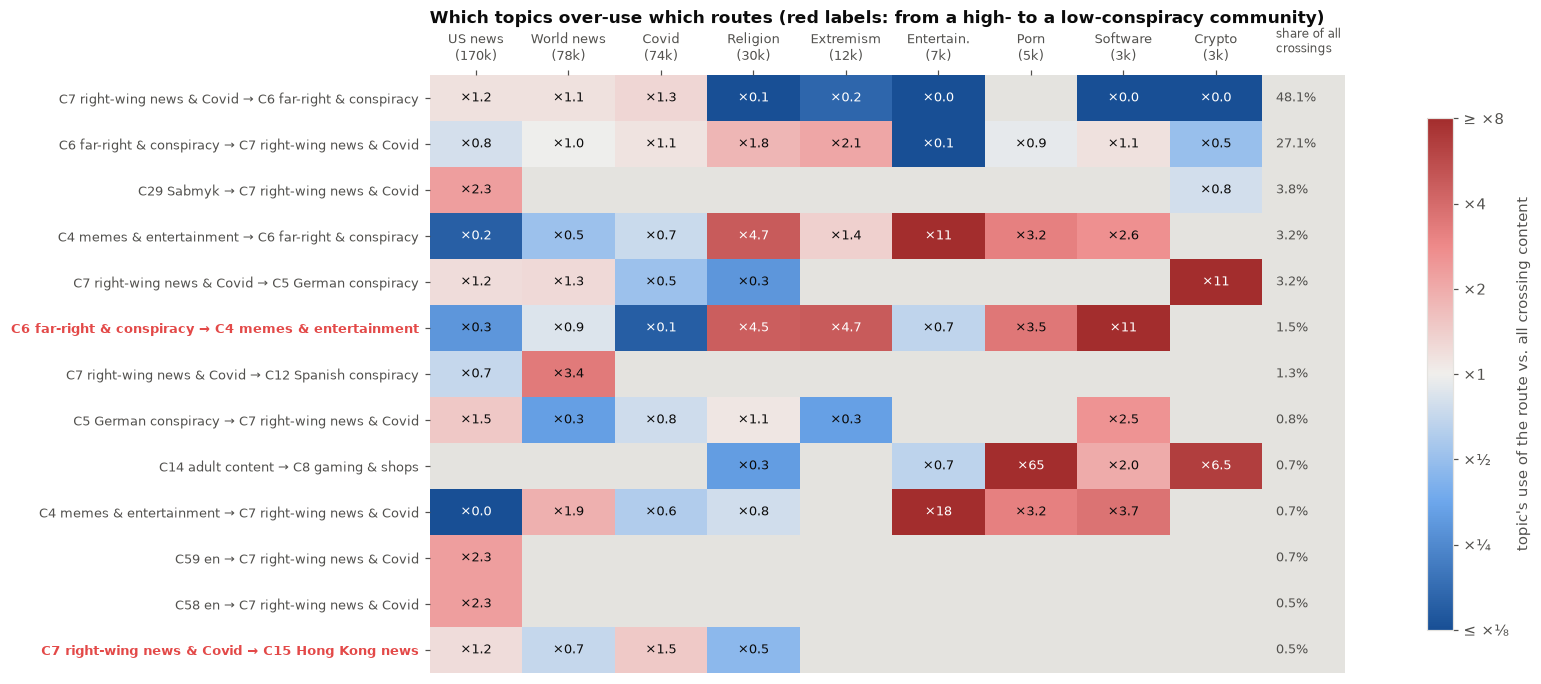

In [10]:
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
SHORT_T = {"US news": "US news", "World news": "World news", "Covid": "Covid", "Religion": "Religion",
           "Extremists and radicals": "Extremism", "Entertainment": "Entertain.", "Porn": "Porn",
           "Software": "Software", "Crypto": "Crypto", "Carding": "Carding", "Videogame modding": "Gaming",
           "Indian edu": "Indian edu", "Social": "Social"}
refr = R["all topics"].set_index(["src_id", "dest_id"])
routes = refr.weight.sort_values(ascending=False).head(12).index.tolist()
routes += [r for r in [(6, 4), (7, 15), (4, 6)] if r not in routes]
cols = [t for t in summ.index if t != "all topics" and summ.loc[t, "crossing forwards"] >= 3000]
ratio = pd.DataFrame(index=pd.MultiIndex.from_tuples(routes), columns=cols, dtype=float)
nfw = ratio.copy()
for t in cols:
    rt = R[t].set_index(["src_id", "dest_id"])
    for rte in routes:
        w = rt.weight.get(rte, 0)
        nfw.loc[rte, t] = w
        ratio.loc[rte, t] = (w / rt.weight.sum()) / refr.share_of_topic_crossing[rte]

DIV = LinearSegmentedColormap.from_list("div", ["#184f95", "#6da7ec", "#f0efec", "#ee8a8a", "#a32d2d"])
L = np.log2(ratio.astype(float).clip(1 / 8, 8)).to_numpy()
fig, ax = plt.subplots(figsize=(12, 0.42 * len(routes) + 1.6))
im = ax.imshow(np.ma.masked_where(nfw.to_numpy() < 30, L), cmap=DIV, norm=TwoSlopeNorm(0, -3, 3), aspect="auto")
ax.set_facecolor("#e4e3df")
for i in range(len(routes)):
    for j in range(len(cols)):
        if nfw.iat[i, j] >= 30:
            v = ratio.iat[i, j]
            ax.text(j, i, f"×{v:.1f}" if v < 10 else f"×{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(L[i, j]) > 2 else plots.INK)
    ax.text(len(cols) - 0.35, i, f"{refr.share_of_topic_crossing[routes[i]]:.1%}", ha="left", va="center", fontsize=8.5, color=plots.INK_2)
lab = lambda c: f"C{c} {comm.loc[c, 'name']}"
ax.set_yticks(range(len(routes)), [f"{lab(a)} → {lab(b)}" for a, b in routes], fontsize=8.5)
for t, (a, b) in zip(ax.get_yticklabels(), routes):
    if comm.loc[a, "level"] == "high" and comm.loc[b, "level"] == "low":
        t.set_color(plots.SERIES[7]); t.set_fontweight("bold")
ax.set_xticks(range(len(cols)), [f"{SHORT_T[t]}\n({summ.loc[t, 'crossing forwards'] / 1e3:,.0f}k)" for t in cols], fontsize=8.5)
ax.xaxis.tick_top()
ax.text(len(cols) - 0.35, -0.9, "share of all\ncrossings", ha="left", va="bottom", fontsize=8, color=plots.INK_2)
ax.set_xlim(-0.5, len(cols) + 0.4); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.08, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_yticklabels(["≤ ×⅛", "×¼", "×½", "×1", "×2", "×4", "≥ ×8"]); cb.set_label("topic's use of the route vs. all crossing content")
ax.set_title("Which topics over-use which routes (red labels: from a high- to a low-conspiracy community)", loc="left",
             fontsize=11, fontweight="bold", pad=34)
plots.savefig(fig, "03b_fig2_route_topic_matrix", OUT)
plt.show()

**Figure 3.** The same matrix with the topic of the **destination** channel (the one that reposted) instead
of the source. It answers a different question: which kinds of channels receive content on each route.
Same rows and columns as Figure 2. Exploratory.

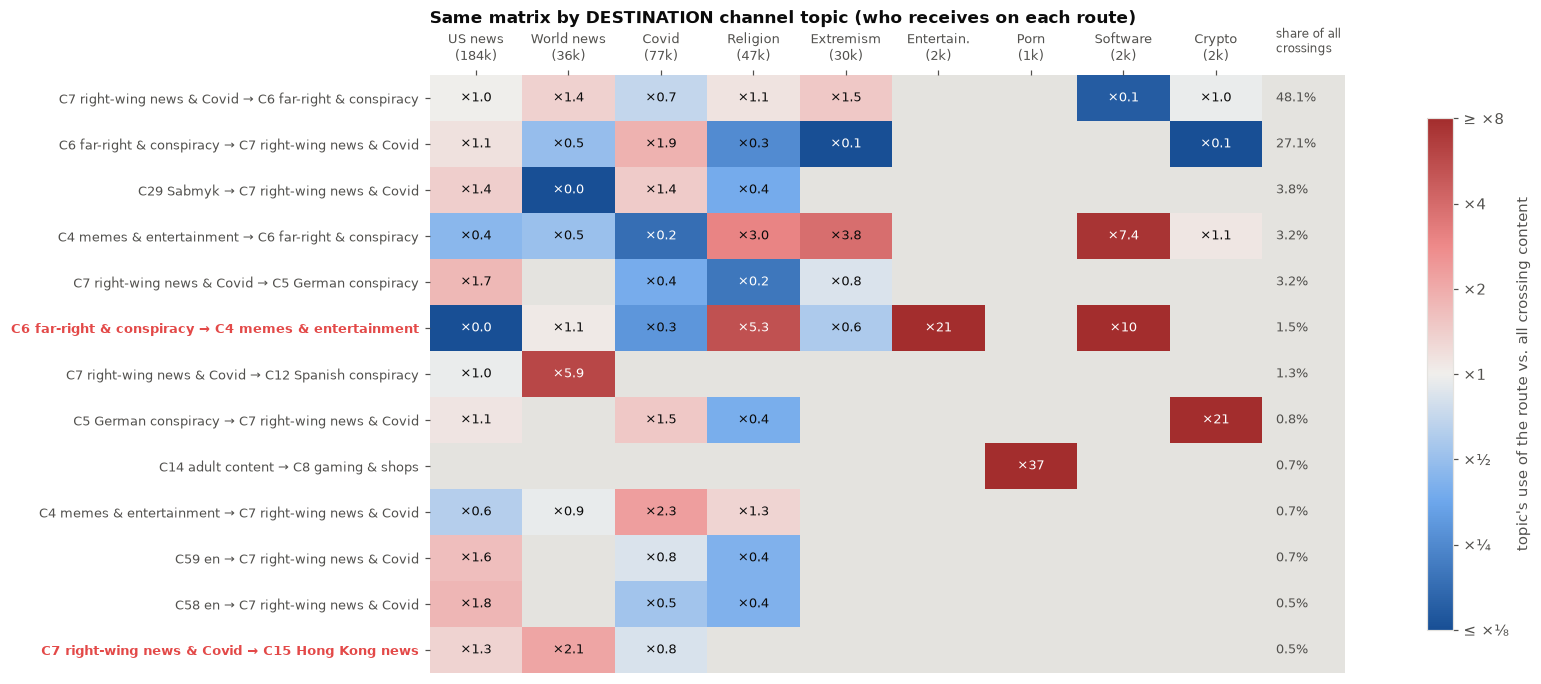

cells comparable in both: 45; same direction (both >1 or both <1): 29


c:\Users\guilh\GitHub\topic-permeability\.venv\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: divide by zero encountered in log2
  result = func(self.values, **kwargs)
c:\Users\guilh\GitHub\topic-permeability\.venv\Lib\site-packages\pandas\core\internals\blocks.py:347: RuntimeWarning: divide by zero encountered in log2
  result = func(self.values, **kwargs)


In [11]:
cross_d = cross.assign(topic=cross.dest_id.map(channels.ch_topic))
Rd = {t: routes_for(cross_d[cross_d.topic == t]) for t in cols}
ratio_d, nfw_d = ratio.copy(), nfw.copy()
for t in cols:
    rt = Rd[t].set_index(["src_id", "dest_id"])
    for rte in routes:
        w = rt.weight.get(rte, 0)
        nfw_d.loc[rte, t] = w
        ratio_d.loc[rte, t] = (w / rt.weight.sum()) / refr.share_of_topic_crossing[rte] if rt.weight.sum() else np.nan
tot_d = {t: int(Rd[t].weight.sum()) for t in cols}

Ld = np.log2(ratio_d.astype(float).clip(1 / 8, 8)).to_numpy()
fig, ax = plt.subplots(figsize=(12, 0.42 * len(routes) + 1.6))
im = ax.imshow(np.ma.masked_where(nfw_d.to_numpy() < 30, Ld), cmap=DIV, norm=TwoSlopeNorm(0, -3, 3), aspect="auto")
ax.set_facecolor("#e4e3df")
for i in range(len(routes)):
    for j in range(len(cols)):
        if nfw_d.iat[i, j] >= 30:
            v = ratio_d.iat[i, j]
            ax.text(j, i, f"×{v:.1f}" if v < 10 else f"×{v:.0f}", ha="center", va="center", fontsize=8.5,
                    color="white" if abs(Ld[i, j]) > 2 else plots.INK)
    ax.text(len(cols) - 0.35, i, f"{refr.share_of_topic_crossing[routes[i]]:.1%}", ha="left", va="center", fontsize=8.5, color=plots.INK_2)
ax.set_yticks(range(len(routes)), [f"{lab(a)} → {lab(b)}" for a, b in routes], fontsize=8.5)
for t, (a, b) in zip(ax.get_yticklabels(), routes):
    if comm.loc[a, "level"] == "high" and comm.loc[b, "level"] == "low":
        t.set_color(plots.SERIES[7]); t.set_fontweight("bold")
ax.set_xticks(range(len(cols)), [f"{SHORT_T[t]}\n({tot_d[t] / 1e3:,.0f}k)" for t in cols], fontsize=8.5)
ax.xaxis.tick_top()
ax.text(len(cols) - 0.35, -0.9, "share of all\ncrossings", ha="left", va="bottom", fontsize=8, color=plots.INK_2)
ax.set_xlim(-0.5, len(cols) + 0.4); ax.grid(False)
for sp in ax.spines.values(): sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.08, ticks=[-3, -2, -1, 0, 1, 2, 3])
cb.ax.set_yticklabels(["≤ ×⅛", "×¼", "×½", "×1", "×2", "×4", "≥ ×8"]); cb.set_label("topic's use of the route vs. all crossing content")
ax.set_title("Same matrix by DESTINATION channel topic (who receives on each route)", loc="left", fontsize=11, fontweight="bold", pad=34)
plots.savefig(fig, "03b_fig3_route_topic_matrix_dest", OUT)
plt.show()
d = (np.log2(ratio_d.astype(float)) - np.log2(ratio.astype(float))).where((nfw >= 30) & (nfw_d >= 30))
print(f"cells comparable in both: {int(d.notna().sum().sum())}; same direction (both >1 or both <1): "
      f"{int(((ratio > 1) == (ratio_d > 1))[d.notna()].sum().sum())}")